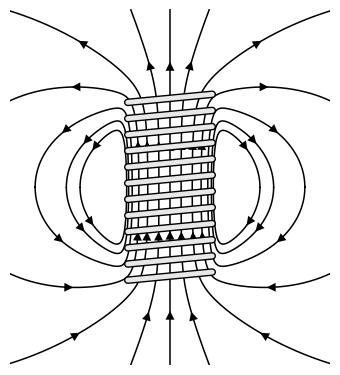

In [3]:
"""
Electromagnet / solenoid with magnetic field lines (matplotlib).

The field is the exact on-axis-symmetric field of a stack of circular current
loops (computed with elliptic integrals), then drawn with streamlines seeded
so that they are evenly spaced in magnetic flux (like a textbook drawing).

# https://claude.ai/share/00de2d35-e39c-4a87-9b8e-0cc7c10647ce

"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from scipy.special import ellipk, ellipe

def draw_coil():
    # ---------------- parameters ----------------
    a = 1.0            # coil radius
    L = 4.0            # coil length
    n_turns = 12       # drawn turns (also used for the field)
    soft = 0.15        # softening so the field is finite near the wires
    n_lines = 11       # number of field lines per side
    xlim, zlim = 3.6, 4
    
    # ---------------- field of a stack of loops ----------------
    def loop_field(r, z, z0, a=a, soft=soft):
        """(B_r, B_z) of a unit-current loop of radius a at height z0 (mu0/2pi = 1 units)."""
        zz = z - z0
        r = np.maximum(r, 1e-6)
        d2 = (a + r) ** 2 + zz ** 2 + soft ** 2
        k2 = np.clip(4 * a * r / d2, 0, 0.999999)
        K, E = ellipk(k2), ellipe(k2)
        d2m = (a - r) ** 2 + zz ** 2 + soft ** 2
        pref = 1.0 / np.sqrt(d2)
        Bz = pref * (K + (a**2 - r**2 - zz**2) / d2m * E)
        Br = pref * (zz / r) * (-K + (a**2 + r**2 + zz**2) / d2m * E)
        return Br, Bz
    
    z_turns = np.linspace(-L / 2, L / 2, n_turns)       # drawn windings
    z_field = np.linspace(-L / 2, L / 2, 80)            # many loops -> smooth field
    
    def B_total(r, z):
        Br = np.zeros_like(r); Bz = np.zeros_like(r)
        for z0 in z_field:
            br, bz = loop_field(r, z, z0)
            Br += br / len(z_field); Bz += bz / len(z_field)
        return Br, Bz
    
    # grid in the x–z plane (x is signed radius)
    x = np.linspace(-xlim, xlim, 500)
    z = np.linspace(-zlim, zlim, 700)
    X, Z = np.meshgrid(x, z)
    Br, Bz = B_total(np.abs(X), Z)
    Bx = np.sign(X) * Br
    
    # ---------------- field-line tracing ----------------
    from scipy.interpolate import RegularGridInterpolator
    fx = RegularGridInterpolator((z, x), Bx, bounds_error=False, fill_value=np.nan)
    fz = RegularGridInterpolator((z, x), Bz, bounds_error=False, fill_value=np.nan)
    
    def direction(p):
        v = np.array([fx([[p[1], p[0]]])[0], fz([[p[1], p[0]]])[0]])
        n = np.hypot(*v)
        return v / n if np.isfinite(n) and n > 0 else None
    
    def trace_upper(x0, ds=0.02, max_steps=6000):
        """Follow the field from the mid-plane (z=0) upward until the line leaves the
        frame or returns to the mid-plane outside the coil."""
        p = np.array([x0, 0.0]); pts = [p.copy()]
        for _ in range(max_steps):
            d1 = direction(p)
            if d1 is None: break
            d2 = direction(p + 0.5 * ds * d1)
            if d2 is None: break
            p = p + ds * d2
            if p[1] < 0: break
            pts.append(p.copy())
        return np.array(pts)
    
    # seeds: evenly spaced across the coil interior, packed towards the wall
    # (those become the big outer loops), plus the central axis line
    frac = np.array([0, 0.25, 0.5, 0.7, 0.85, 0.93, 0.975])
    seeds = sorted({s * f * a for f in frac for s in (-1, 1)})
    
    def arrow(ax, p, d, size=16):
        ax.add_patch(FancyArrowPatch(p - 0.02 * d, p + 0.02 * d, arrowstyle="-|>",
                                     mutation_scale=size, color="k", lw=0, zorder=2))
    
    # ---------------- drawing ----------------
    fig, ax = plt.subplots(figsize=(3.5, 4))
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_xlim(-xlim, xlim); ax.set_ylim(-zlim, zlim)
    
    for x0 in seeds:
        up = trace_upper(x0)
        if len(up) < 3: continue
        down = up[::-1] * [1, -1]                     # mirror image below the mid-plane
        full = np.vstack([down, up[1:]])
        ax.plot(full[:, 0], full[:, 1], "k", lw=1.1, zorder=2)
        # arrows: inside the coil (z ~ 1.0) and part-way round the outside (70 %)
        for sgn in (1, -1):
            i = np.argmax(up[:, 1] >= 1.0)
            j = int(0.7 * (len(up) - 1))
            inside = abs(x0) < 0.8 * a            # interior arrows only on the inner lines
            for idx in ((i, j) if inside else (j,)):
                if idx < 1 or idx >= len(up) - 1: continue
                d = up[idx + 1] - up[idx - 1]; d /= np.hypot(*d)
                p = up[idx] * [1, sgn]
                if sgn == -1: d = -d * [1, -1]    # flow direction is reversed in the mirror image
                arrow(ax, p, d)
    
    # copper windings (slanted wires wrapped around the core)
    pitch = z_turns[1] - z_turns[0]
    for z0 in z_turns:
        xs = np.array([-a * 0.95, a * 0.95])
        zs = np.array([z0 - pitch * 0.25, z0 + pitch * 0.25])
        ax.plot(xs, zs, color="k", lw=5.5, solid_capstyle="round", zorder=4)
        ax.plot(xs, zs, color="#e8e8e8", lw=3.5, solid_capstyle="round", zorder=4.1)
    
    # # lead wires with current arrows
    # top, bot = z_turns[-1], z_turns[0]
    # ax.plot([a * 0.95, 2.2], [top + pitch * 0.25] * 2, "k", lw=3, zorder=4)
    # ax.plot([a * 0.95, 2.2], [bot - pitch * 0.25] * 2, "k", lw=3, zorder=4)
    # for zz, dx in ((top + pitch * 0.25, -1), (bot - pitch * 0.25, 1)):
    #     start, end = (2.2, zz), (1.5, zz)
    #     if dx == 1: start, end = end, start
    #     ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=18,
    #                                  color="red", lw=2.5, zorder=5))
    #     ax.text(1.85, zz + (0.22 if dx == -1 else -0.38), "I", color="red",
    #             fontsize=14, style="italic", weight="bold", ha="center")
    # ax.text(2.45, top + pitch * 0.25, "–", fontsize=20, weight="bold", va="center")
    # ax.text(2.45, bot - pitch * 0.25, "+", fontsize=20, weight="bold", va="center")
    
    plt.tight_layout()
    plt.savefig("inductor_coil.png", dpi=300,bbox_inches='tight')
    plt.show()
    plt.close()


draw_coil()